In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

In [2]:
# Load breast cancer dataset
data = load_breast_cancer()

# Create DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)

# Add target column
df['target'] = data.target

print("First Five Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nTarget Names:")
print(data.target_names)

print("\nMissing Values:")
print(df.isnull().sum().sum())

First Five Rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area 

In [3]:
X = df.drop('target', axis=1)

y = df['target']

print("Input Features Shape:", X.shape)

print("Target Shape:", y.shape)

Input Features Shape: (569, 30)
Target Shape: (569,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed Successfully!")

Feature Scaling Completed Successfully!


In [6]:
model = LogisticRegression(max_iter=10000)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [7]:
y_pred = model.predict(X_test_scaled)

print("Actual Values:")
print(y_test[:10].values)

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[0 1 0 1 0 1 1 0 0 0]

Predicted Values:
[0 1 0 1 0 1 1 0 0 0]


In [8]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.9824561403508771
Accuracy Percentage: 98.24561403508771 %


Confusion Matrix:
[[41  1]
 [ 1 71]]


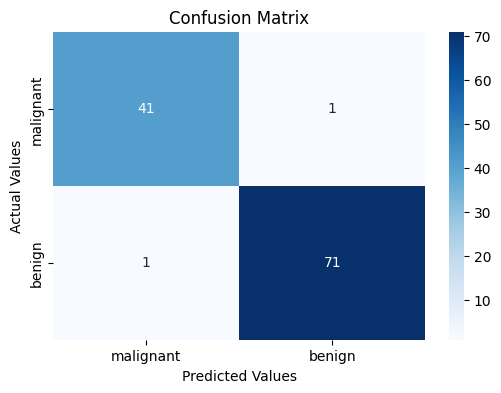

In [9]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.title("Confusion Matrix")

plt.show()

In [10]:
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



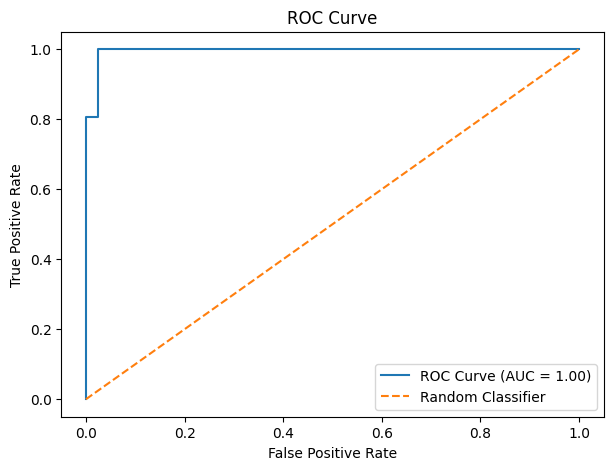

AUC Score: 0.9953703703703703


In [11]:
# Get prediction probabilities
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
auc = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc:.2f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

print("AUC Score:", auc)

In [12]:
# Take one sample from the test dataset
new_sample = X_test.iloc[[0]]

# Scale the sample
new_sample_scaled = scaler.transform(new_sample)

# Predict class
prediction = model.predict(new_sample_scaled)

# Display result
print("Predicted Class:", data.target_names[prediction[0]])

Predicted Class: malignant
